# MultiSegment Demo

This notebook demonstrates the functionality of the MultiSegment object, for analyzing data from multiple segments at once.

The two classes that will be introduced are

* segment_analysis.MultiSegment 
* playbacks_analysis.PlaybacksManager (which uses MultiSegment)

### First, imports and loading data file

In [1]:
from __future__ import print_function

import cPickle as pickle
import matplotlib.pyplot as plt
import numpy as np
import os

from segment_analysis import MultiSegment
from playbacks_analysis import PlaybacksManager

import config

/auto/fhome/kevin/Projects/songephys/env/local/lib/python2.7/site-packages/h5py/__init__.py:34: FutureWarning: Conversion of the second argument of issubdtype from `float` to `np.floating` is deprecated. In future, it will be treated as `np.float64 == np.dtype(float).type`.
  from ._conv import register_converters as _register_converters


In [2]:
session_dir = "../data/birds/GreYel3594M/GreYel3594M___170919_094646"
bird, session = session_dir.split("/")[-2:]
data_path = os.path.join(session_dir, "spikes", "{}-sorted-result.pkl").format(session)

In [3]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)

## I. Basics

### First, lets create a MultiSegment object with 10 random segments

In [4]:
# sample 10 random segments
segments = np.random.choice(block.segments, size=10, replace=False)
multiseg_random = MultiSegment(segments=segments)

In [5]:
print(multiseg_random)

MultiSegment with 10 Segments, 6 Units, t_start=-0.0s, t_stop=4.46796666667s
{}


#### The annotations show any annotations that all the segments in the MultiSegment share

For our random set, there are probably none

In [6]:
print(multiseg_random.annotations)

{}


### We can access the analogsignals for any segment

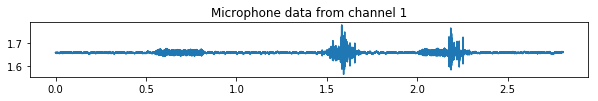

In [7]:
plt.figure(figsize=(10, 1))

# This is the 2nd channel on signal 0, which is the microphone data
t, sig, sr = multiseg_random.get_analogsignal(seg_idx=0, signal=0, channel=1)
plt.plot(t, sig)
plt.title("Microphone data from channel 1")
plt.show()

### We can access the spike times for any unit included in these segments

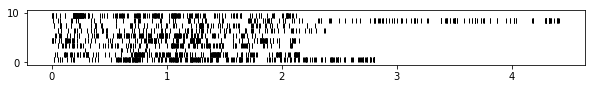

In [8]:
plt.figure(figsize=(10, 1))

# Spike times is an array of spike arrival times for each segment
# each segment can have a different number of spike arrival times
spike_times = multiseg_random.spike_times(unit=0)
for unit_idx in range(len(spike_times)):
    plt.vlines(spike_times[unit_idx], unit_idx, unit_idx + 1, linewidth=1)
plt.show()

## The MultiSegment object offers helpful plotting helps

The helper functions include `plot_psth`, `plot_spectrogram`, and `plot_raster`. They take an `ax` parameter to display them in a particular matplotlib axis.

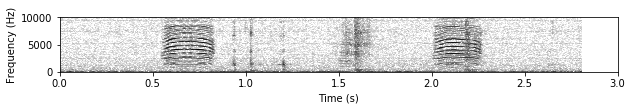

In [9]:
for segment in multiseg_random.segments[:1]:
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 1))
    
    # This function plots the spectrogram parameters for get_analogsignal
    multiseg_random.plotter.plot_spectrogram(segment, signal=0, channel=0, ax=ax)
    ax.set_xlim(0, 3)
    plt.show()

Here is an example of plotting a spike, and then overlaying a psth by creating a new axis that shares the first's x-axis.

Since the stimuli were randomly selected, we shouldn't see much structure in the psth.

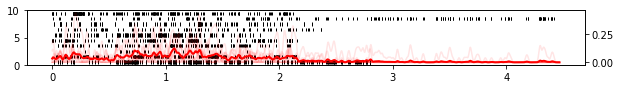

In [10]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 1))
multiseg_random.plotter.plot_raster(unit=0, ax=ax)

ax_psth = ax.twinx()  # create a new axis that shares the same x (time) axis
multiseg_random.plotter.plot_psth(unit=0, ax=ax_psth, color="Red")

plt.show()

## II. Playbacks

For a better example, lets look at responses grouped by playback stimulus.

To do this, I'll use the PlaybacksManager helper, which automatically creates a MultiSegment object for each stimulus.

In [11]:
playbacks_manager = PlaybacksManager(block.segments)
playback_multisegs = playbacks_manager.group_playback_responses()

In [12]:
print(playbacks_manager.stim_ids)

['GreHpi3607M_FAF_DC_0.wav' 'GreHpi3607M_FAF_DC_1.wav'
 'GreHpi3607M_FAF_DC_2.wav' 'GreHpi3607M_FAF_Te_0.wav'
 'GreHpi3607M_FAF_Te_1.wav' 'GreHpi3607M_FAF_Te_2.wav'
 'GreHpi3607M_MAF_DC_0.wav' 'GreHpi3607M_MAF_DC_1.wav'
 'GreHpi3607M_MAF_So_0.wav' 'GreHpi3607M_MAF_So_1.wav'
 'GreHpi3607M_MAF_So_2.wav' 'GreHpi3607M_MAF_So_3.wav'
 'GreHpi3607M_MAF_Te_0.wav' 'GreHpi3607M_MAT_DC_0.wav'
 'GreHpi3607M_MAT_So_0.wav' 'GreHpi3607M_MAT_So_1.wav'
 'GreHpi3607M_MAT_So_2.wav' 'GreHpi3607M_MAT_So_3.wav'
 'GreHpi3607M_MAT_Te_0.wav' 'GreHpi3607M_MAT_Te_1.wav'
 'GreHpi3607M_MAT_Te_2.wav' 'GreHpi3607M_MJF_So_0.wav'
 'GreHpi3607M_MJF_So_1.wav' 'GreHpi3607M_MJF_So_2.wav']


### Lets take the responses to one stimulus and plot the psth, raster, and spectrogram on one plot

Note that to plot the spectrogram corresponding to a playback stimulus, specify `signal="playback"` and `channel=None` when calling `plot_spectrogram()`

In [13]:
stim_multiseg = playback_multisegs["GreHpi3607M_MAT_So_2.wav"]

In [14]:
for key, value in stim_multiseg.annotations.iteritems():
    print("{}: {}".format(key, value))

vocalization_type: So
sound_type: playback
vocalizer: tutor
playback_file: data/birds/GreYel3594M/GreYel3594M___170919_094646/stimuli/TutFamBos/GreHpi3607M_MAT_So_2.wav


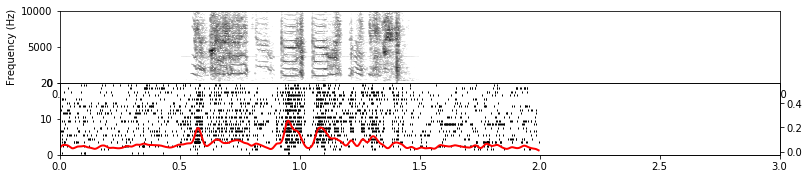

In [15]:
fig = plt.figure(figsize=(10, 1))

# Plot spectrogram on its own axis
spectrogram_ax = fig.add_axes([0, 1, 1, 1])
stim_multiseg.plotter.plot_spectrogram(seg=0, signal="playback", channel=None,
                                       ax=spectrogram_ax)

# Plot raster and psth on top of each other
raster_ax = fig.add_axes([0, 0, 1, 1])
stim_multiseg.plotter.plot_raster(unit=0, ax=raster_ax)
psth_ax = raster_ax.twinx()
stim_multiseg.plotter.plot_psth(unit=0, ax=psth_ax, color="Red", alpha=0.0)

# MAKE SURE all axes have the same x-scale
raster_ax.set_xlim(0, 3)
spectrogram_ax.set_xlim(0, 3)

plt.show()

## III. Segment Alignment

Now for the most confusing part.

MultiSegment provides a way to re-align segments. This doesn't change the data under the hood, but will always apply a fixed time offset (in seconds) unique to each segment.

The actual computation of the offsets must be done separately.

Here I will give a simple example of re-aligning the random segments to a point 1 second before the end.

#### First, the original sounds

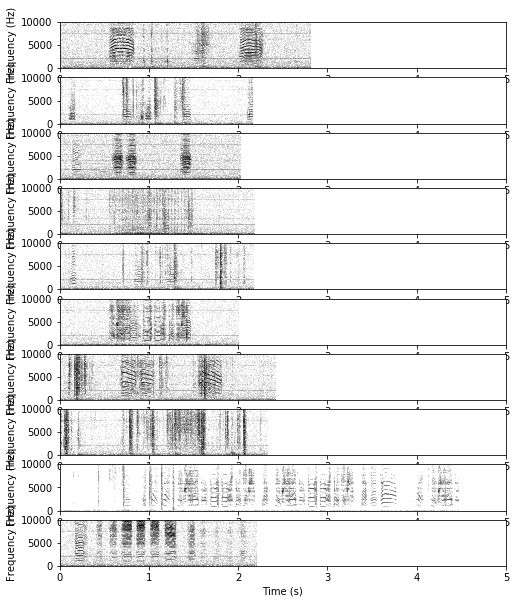

In [16]:
fig, axes = plt.subplots(nrows=10, ncols=1, figsize=(8, 10))
for i, segment in enumerate(multiseg_random):
    multiseg_random.plotter.plot_spectrogram(segment, signal=0, channel=0, ax=axes[i])
    axes[i].set_xlim(0, 5)
plt.show()

#### Second, compute offsets

In [17]:
offsets = []
for segment in multiseg_random:
    # Using .item() because of annoying pyquantities unit stuff
    # pyquantities... good in theory but really annoying 
    offset = (segment.t_stop - segment.t_start).item() - 1.0
    offsets.append(offset)

In [18]:
print(offsets)

[1.8046333333334132, 1.1563333333333503, 1.0200000000000102, 1.1819000000000415, 1.1692999999995664, 0.995833333333394, 1.4121999999999844, 1.3246333333336224, 3.4679666666670528, 1.1981000000000677]


#### Third, apply the offsets

When computing psths or binarized spike trains

In [19]:
multiseg_random.set_offsets(np.array(offsets))

In [20]:
offsets

[1.8046333333334132,
 1.1563333333333503,
 1.0200000000000102,
 1.1819000000000415,
 1.1692999999995664,
 0.995833333333394,
 1.4121999999999844,
 1.3246333333336224,
 3.4679666666670528,
 1.1981000000000677]

#### Fourth, plot the spectrograms

Notice that running the exact same code as the cell above, the spectrograms will be aligned to their new "zero" point. The rest of the data is still there but with negative time values.

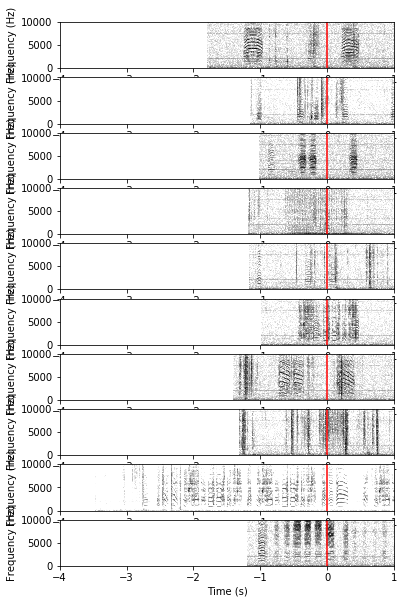

In [21]:
fig, axes = plt.subplots(nrows=10, ncols=1, figsize=(6, 10))
for i, segment in enumerate(multiseg_random):
    multiseg_random.plotter.plot_spectrogram(segment, signal=0, channel=0, ax=axes[i])
    
    # Just drawing a red line at 0
    axes[i].vlines([0], *axes[i].get_ylim(), color="Red")
    axes[i].set_xlim(-4, 1)
    
plt.show()